# The fitting figures from the saved fits (Fig. 4, Figs. 9 to 11)

Reads the saved fits of `fit_grid_cells` and `fit_place_cells` and draws the panels of Fig. 4
and Figs. 9 to 11 into `figures/fitting/`, svg and png side by side with the text kept as
text, so that the figures can be assembled and lettered in Inkscape. Nothing is refitted. The
maps beyond the arena are generated in closed form from the saved $R$ and wavevectors
(App. C) and checked against the saved reconstruction first.

**Fig. 4.** For each dataset a reconstruction panel with the data and model row labels and an
extrapolation panel without: the eight best units by the panel's own score, data over model,
the correlation above each pair.

**Figs. 9 to 11.** One file per panel, each spanning the text width: every unit of the
reconstruction and of the extrapolation, best to worst, 21 maps per row, and every unit over an
arena of twice the side length, the data in a gray frame above the model with the recorded
arena outlined in black.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures" / "fitting"
FITS = {
    "grid": REPO_ROOT / "data" / "gc_fit_commuting.npz",
    "place": REPO_ROOT / "data" / "ca1_fit_one_animal_si0.50.npz",
}

TEXT_WIDTH = 5.5  # NeurIPS text block, inches (38 mm margins on letter paper)
N_MAIN = 8  # units per main-figure panel
MAIN_MAP = 0.31  # inches per rate map in the Fig. 4 panels
APP_COLS = 21  # 102 and 103 units both take five pairs of rows at 21 maps per row
LABEL_PAD = 0.16  # room left of the maps for the row labels, inches
APP_MAP = (TEXT_WIDTH - LABEL_PAD) / APP_COLS  # the gallery with its row labels spans the text width
BEYOND_BINS = 64  # doubled arena at the data's pixel size
FONT = 7  # scores and row labels in the Fig. 4 panels, points
FONT_APP = 6  # the same in the full galleries
CLIP = 99  # percentile of the data map that saturates the shared color scale

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["figure.dpi"] = 200  # display in the notebook; the saved png uses its own dpi
CMAP = plt.get_cmap("viridis").copy()
CMAP.set_bad("0.9")  # the blank frame around the arena in the beyond-arena panels
FIGURE_DIR.mkdir(exist_ok=True)

## Drawing

A gallery is rows alternating data and model for a list of units, each pair of rows labeled
"data" and "model" on the left.

In [2]:
def gallery_size(n_units, n_cols, map_size, scores=True, row_labels=True):
    """Width and height in inches of a gallery drawn with `draw_gallery`."""
    n_rows = 2 * int(np.ceil(n_units / n_cols))
    title_pad = 0.17 * map_size / 0.31 if scores else 0.0
    return n_cols * map_size + (LABEL_PAD if row_labels else 0.0), n_rows * map_size + (n_rows // 2) * title_pad


def draw_gallery(fig, data, model, scores, units, *, n_cols, box=None, box_color="w", row_labels=True, font=FONT):
    """Rows alternating data and model for `units`, in that order, filling `fig` (a Figure or SubFigure).

    `data` and `model` are indexed (unit, bins_x, bins_y) and drawn transposed with the origin
    at the lower left; NaN in `data` is drawn blank. `scores` prints one number above each pair,
    or nothing if None. `box` outlines the pixel square `(lo, hi)` on both rows. Row labels
    "data" and "model" go left of every pair of rows.
    """
    n_rows = 2 * int(np.ceil(len(units) / n_cols))
    axs = fig.subplots(n_rows, n_cols, squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for j, k in enumerate(units):
        row, col = 2 * (j // n_cols), j % n_cols
        vmax = np.nanpercentile(data[k], CLIP)
        axs[row, col].imshow(data[k].T, origin="lower", cmap=CMAP, vmin=0, vmax=vmax)
        axs[row + 1, col].imshow(model[k].T, origin="lower", cmap=CMAP, vmin=0, vmax=vmax)
        if scores is not None:
            axs[row, col].set_title(f"{scores[k]:.2f}", fontsize=font, pad=2)
        if box is not None:
            lo, hi = box
            for ax in (axs[row, col], axs[row + 1, col]):
                ax.add_patch(
                    plt.Rectangle(
                        (lo - 0.5, lo - 0.5), hi - lo, hi - lo, fill=False, edgecolor=box_color, linewidth=0.6
                    )
                )
    if row_labels:
        for row in range(0, n_rows, 2):
            for label, ax in zip(("data", "model"), axs[row : row + 2, 0]):
                ax.text(-0.08, 0.5, label, rotation=90, va="center", ha="right", fontsize=font, transform=ax.transAxes)
    return axs


def panel(data, model, scores, units, *, n_cols, map_size, **kwargs):
    """One gallery as its own figure."""
    fig = plt.figure(
        figsize=gallery_size(len(units), n_cols, map_size, scores is not None, kwargs.get("row_labels", True)),
        layout="constrained",
    )
    fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.0, hspace=0.0)
    draw_gallery(fig, data, model, scores, units, n_cols=n_cols, **kwargs)
    return fig


def save(fig, stem, png_only=False):
    """Write png and svg; the figure stays open so the cell displays it."""
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=250, bbox_inches="tight", pad_inches=0.02)
    if not png_only:
        fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight", pad_inches=0.02)

## The saved fits

Per dataset: the data, the reconstruction with its per-unit correlation, the extrapolation
from the central three quarters with its correlation over the part of the arena not trained
on, and the bin range of the trained square.

In [3]:
def load(path):
    d = np.load(path)
    inner = d["inner"]
    mid = inner[inner.shape[0] // 2]
    lo, hi = int(np.argmax(mid)), int(len(mid) - np.argmax(mid))
    fit = {
        "data": d["experimental"],
        "model": d["generated"],
        "extrapolated": d["extrapolated"],
        "r": d["correlation"],
        "r_out": d["outer_correlation"],
        "box": (lo, hi),
        "R": d["R"].astype(np.float64),
        "wavevectors": d["wavevectors"].astype(np.float64),
    }
    fit["by_r"], fit["by_r_out"] = np.argsort(-fit["r"]), np.argsort(-fit["r_out"])
    return fit


fits = {name: load(path) for name, path in FITS.items()}
for name, f in fits.items():
    print(f"{name}: {len(f['data'])} units, trained square pixels {f['box'][0]}..{f['box'][1]}")

grid: 102 units, trained square pixels 4..28
place: 103 units, trained square pixels 4..28


## Fig. 4

Fig. 4 panels: 2.64 and 2.48 x 0.79 in, leaving 0.38 in between


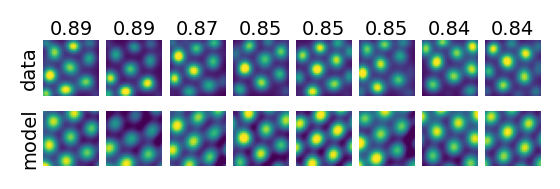

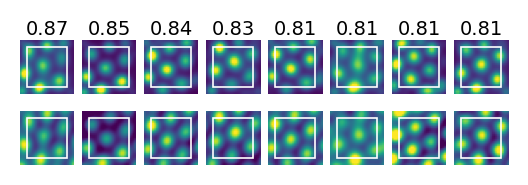

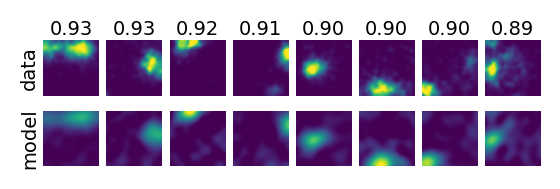

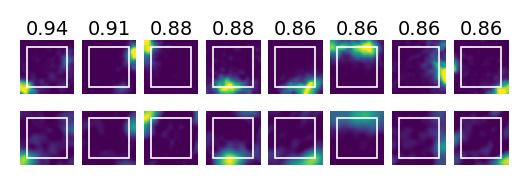

In [4]:
for name, f in fits.items():
    common = {"n_cols": N_MAIN, "map_size": MAIN_MAP}
    save(panel(f["data"], f["model"], f["r"], f["by_r"][:N_MAIN], **common), f"main_{name}_reconstruction")
    save(
        panel(
            f["data"], f["extrapolated"], f["r_out"], f["by_r_out"][:N_MAIN], box=f["box"], row_labels=False, **common
        ),
        f"main_{name}_extrapolation",
    )
w_left, h = gallery_size(N_MAIN, N_MAIN, MAIN_MAP)
w_right, _ = gallery_size(N_MAIN, N_MAIN, MAIN_MAP, row_labels=False)
print(f"Fig. 4 panels: {w_left:.2f} and {w_right:.2f} x {h:.2f} in, leaving {TEXT_WIDTH - w_left - w_right:.2f} in between")

## Figs. 9 and 10: every unit

Reconstruction and extrapolation per dataset, units ordered best to worst by the panel's own
score.

app_grid_reconstruction_all: 5.50 x 3.24 in


app_grid_extrapolation_all: 5.50 x 3.24 in


app_place_reconstruction_all: 5.50 x 3.24 in


app_place_extrapolation_all: 5.50 x 3.24 in


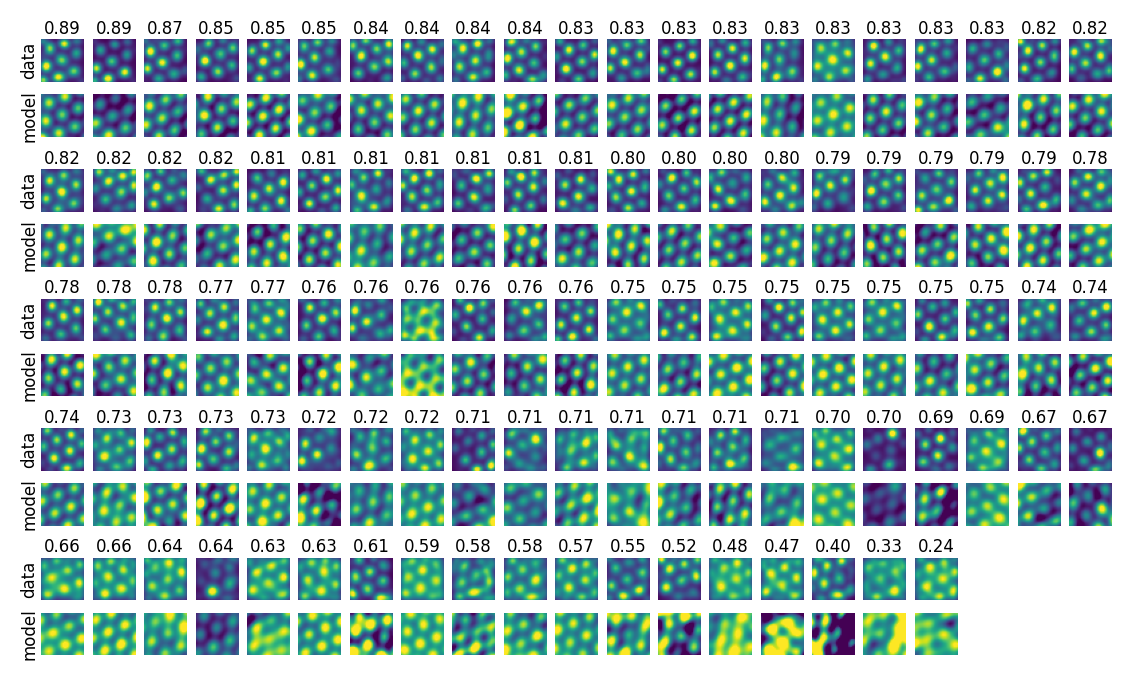

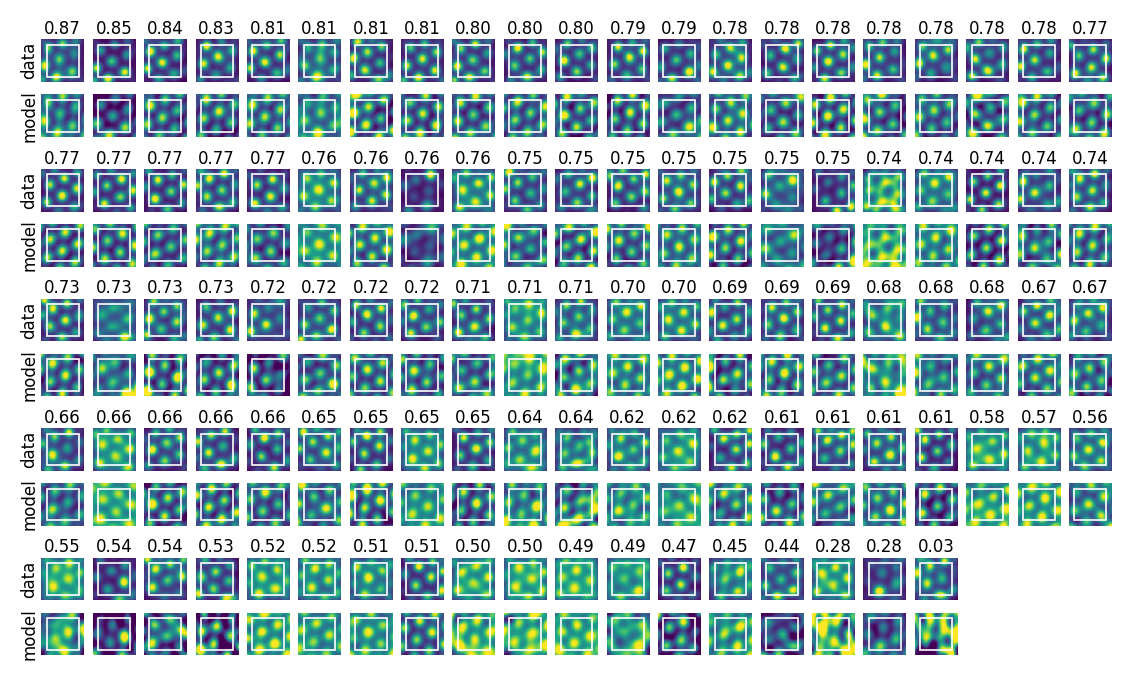

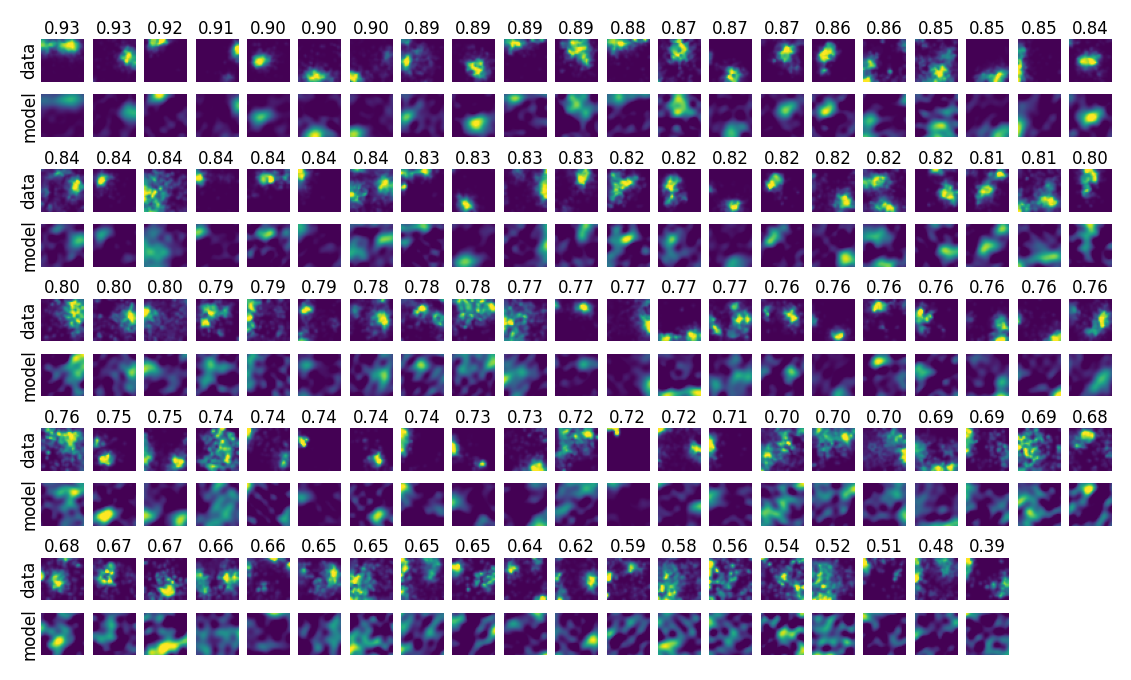

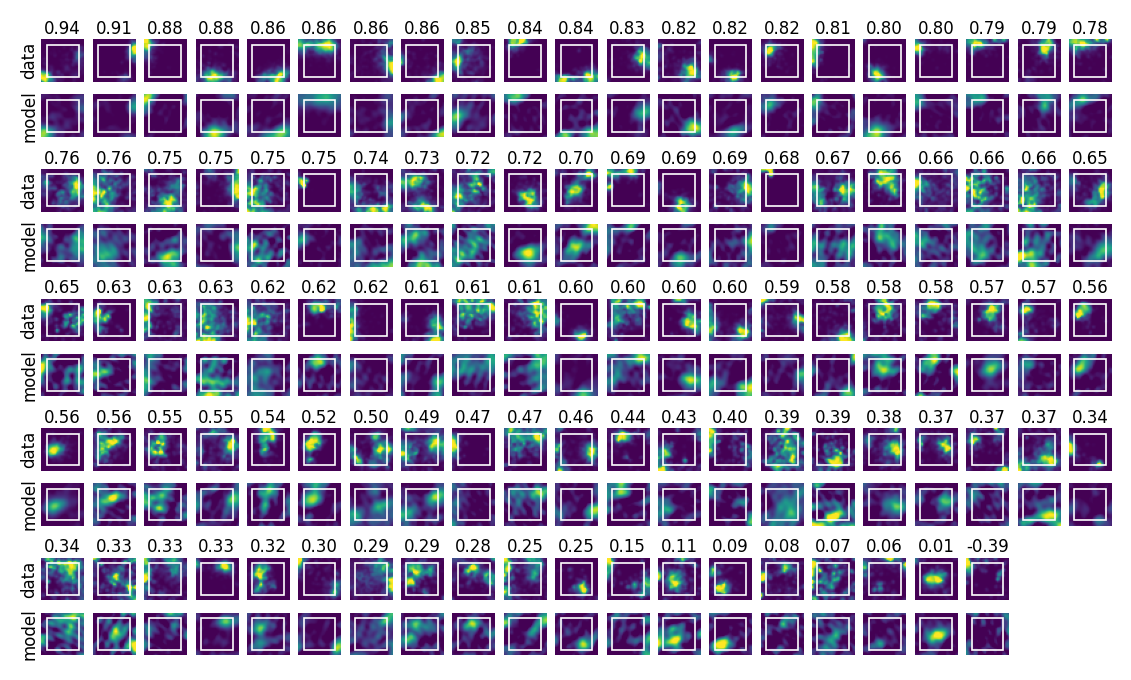

In [5]:
for name, f in fits.items():
    common = {"n_cols": APP_COLS, "map_size": APP_MAP, "font": FONT_APP}
    for stem, fig in [
        (f"app_{name}_reconstruction_all", panel(f["data"], f["model"], f["r"], f["by_r"], **common)),
        (
            f"app_{name}_extrapolation_all",
            panel(f["data"], f["extrapolated"], f["r_out"], f["by_r_out"], box=f["box"], **common),
        ),
    ]:
        print(f"{stem}: {fig.get_figwidth():.2f} x {fig.get_figheight():.2f} in")
        save(fig, stem)

## Fig. 11: beyond the arena

$\mathbf{p}(x, y) = e^{x G_x + y G_y}\,\mathbf{p}(0, 0)$ over an arena of twice the side length,
evaluated as the block rotations of App. C from the saved $R$ and wavevectors, the arithmetic
of `CommutingGeneratorFit.transport` in numpy. The arena itself is regenerated first and
compared with the saved reconstruction, and the population norm is checked to be constant, as
orthogonal transport requires.

grid: closed form vs saved reconstruction max |diff| 7.1e-08; ||p|| over the doubled arena 0.4565 +/- 7.1e-08


app_grid_beyond_arena_all: 5.50 x 3.24 in


place: closed form vs saved reconstruction max |diff| 3.6e-08; ||p|| over the doubled arena 0.1224 +/- 2.9e-08


app_place_beyond_arena_all: 5.50 x 3.24 in


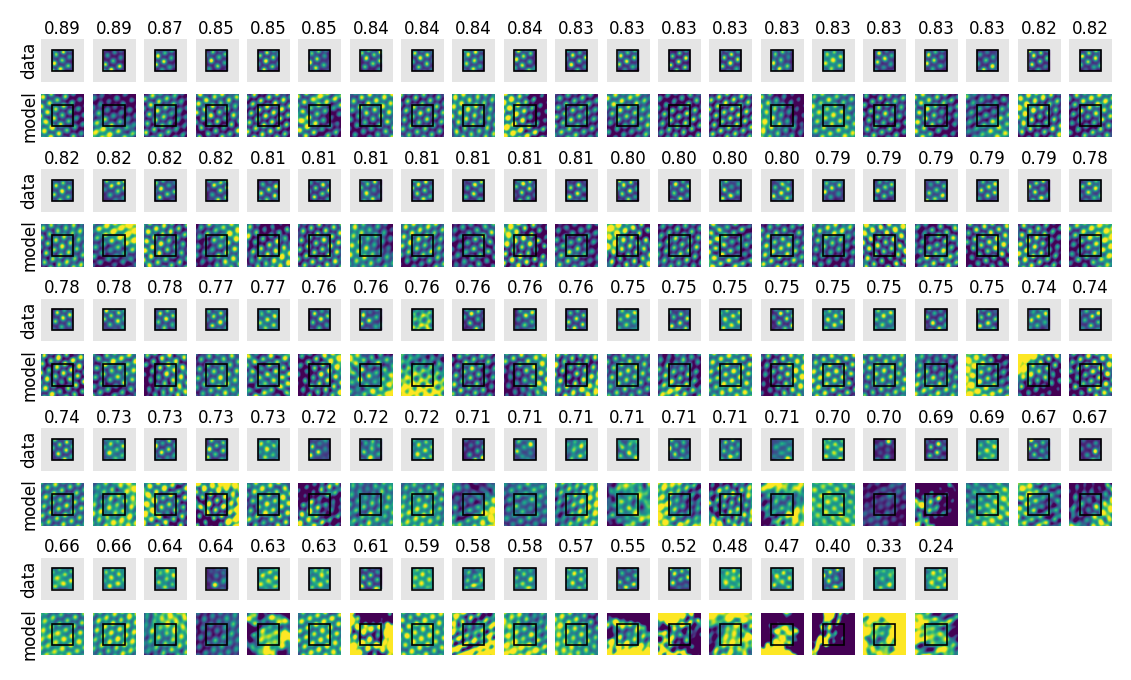

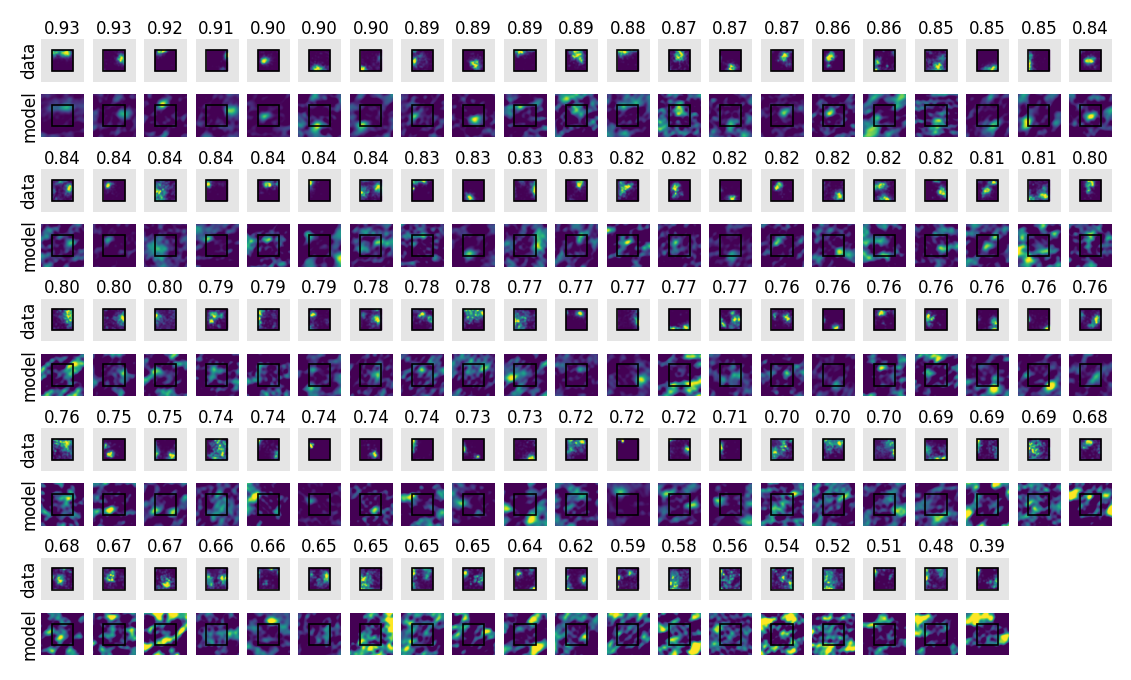

In [6]:
def generate(R, wavevectors, p0, n_bins, extent, arena_size=1.0):
    """Transport `p0` from the center over `n_bins` x `n_bins` bins spanning `extent` arenas, as block rotations."""
    axis = np.arange(n_bins) - n_bins // 2
    gx, gy = np.meshgrid(axis, axis, indexing="ij")
    dr = extent * (2 * arena_size / n_bins) * np.stack([gx.ravel(), gy.ravel()], axis=1)
    n = 2 * len(wavevectors)
    alpha = R @ p0
    Omega = dr @ wavevectors.T  # (positions, pairs)
    c, s = np.cos(Omega), np.sin(Omega)
    a, b = alpha[:n:2], alpha[1:n:2]
    rotated = np.stack([c * a - s * b, s * a + c * b], axis=-1).reshape(len(dr), n)
    alpha_r = np.concatenate([rotated, np.broadcast_to(alpha[n:], (len(dr), len(alpha) - n))], axis=1)
    p = alpha_r @ R
    return p.T.reshape(len(p0), n_bins, n_bins)


def center_in_frame(maps, n_bins_out):
    """The maps centered in a blank frame of `n_bins_out` bins, and the bin range they occupy."""
    n = maps.shape[1]
    lo = (n_bins_out - n) // 2
    frame = np.full((len(maps), n_bins_out, n_bins_out), np.nan, dtype=maps.dtype)
    frame[:, lo : lo + n, lo : lo + n] = maps
    return frame, (lo, lo + n)


for name, f in fits.items():
    n_bins = f["data"].shape[1]
    p0 = f["data"][:, n_bins // 2, n_bins // 2].astype(np.float64)
    check = generate(f["R"], f["wavevectors"], p0, n_bins, extent=1.0)
    beyond = generate(f["R"], f["wavevectors"], p0, BEYOND_BINS, extent=2.0)
    norms = np.linalg.norm(beyond.reshape(len(p0), -1), axis=0)
    print(
        f"{name}: closed form vs saved reconstruction max |diff| {np.abs(check - f['model']).max():.1e}; "
        f"||p|| over the doubled arena {norms.mean():.4f} +/- {norms.std():.1e}"
    )
    framed, arena_box = center_in_frame(f["data"], BEYOND_BINS)
    fig = panel(
        framed,
        beyond,
        f["r"],
        f["by_r"],
        n_cols=APP_COLS,
        map_size=APP_MAP,
        box=arena_box,
        box_color="k",
        font=FONT_APP,
    )
    print(f"app_{name}_beyond_arena_all: {fig.get_figwidth():.2f} x {fig.get_figheight():.2f} in")
    save(fig, f"app_{name}_beyond_arena_all")